# CNN: сборка, обучение и оценка на MNIST




## Установка пакетов


In [1]:
%pip install numpy pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


## 1. Импорты и пути


In [2]:
%matplotlib inline
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    ConfusionMatrixDisplay, RocCurveDisplay,
    accuracy_score, confusion_matrix,
    precision_recall_fscore_support, roc_auc_score,
)

# Находим корень проекта при запуске из проекта, lab2 или lab2/source.
ROOT = Path.cwd()
ROOT = ROOT.parent.parent

sys.path.insert(0, str(ROOT))
from lab_1.source.neural_network import NeuralNetwork
from lab_1.source.layers import Linear, Softmax
from lab2.source.layers import Conv2d, Flatten, MaxPool2d, ReLU

DATA_DIR = ROOT / "lab2/data"
IMAGES_DIR = ROOT / "lab2/images"
IMAGES_DIR.mkdir(parents=True, exist_ok=True)


ModuleNotFoundError: No module named 'lab2'

## 2. Загружаем и готовим данные

In [ ]:
with np.load(DATA_DIR / "mnist.npz", allow_pickle=False) as data:
    images = np.concatenate((data["x_train"], data["x_test"]))
    labels = np.concatenate((data["y_train"], data["y_test"]))

X = images.astype(np.float32)[:, None, :, :] / 255.0
X_train, X_test, y_train, y_test = train_test_split(
    X, labels,
    train_size=0.7,
    random_state=42,
    stratify=labels,
)

print("Обучение: изображения", X_train.shape, "; метки", y_train.shape)
print("Тест: изображения", X_test.shape, "; метки", y_test.shape)


Обучение: изображения (49000, 1, 28, 28) ; метки (49000,)
Тест: изображения (21000, 1, 28, 28) ; метки (21000,)


## 3. Параметры эксперимента



In [ ]:
config = {
    "seed": 42,
    "shuffle_seed": 43,
    "batch_size": 64,
    "epochs": 60,
    "hidden_features": 64,
    "learning_rate": 0.2,
    "target_loss": 0.0001,
}
display(config)


{'seed': 42,
 'shuffle_seed': 43,
 'batch_size': 64,
 'epochs': 60,
 'hidden_features': 64,
 'learning_rate': 0.2,
 'target_loss': 0.0001}

## 4. Собираем CNN 


In [ ]:
rng = np.random.default_rng(config["seed"])

# Эти же объекты используем ниже для сохранения весов.
conv = Conv2d(1, 8, 3, rng=rng, padding=1)
hidden = Linear(8 * 14 * 14, config["hidden_features"], rng)
linear = Linear(config["hidden_features"], 10, rng)

model = NeuralNetwork(
    conv,
    ReLU(),
    MaxPool2d(kernel_size=2, stride=2),
    Flatten(),
    hidden,
    ReLU(),
    linear,
    Softmax(),
    learning_rate=config["learning_rate"],
    epochs=config["epochs"],
)


## 5. Цикл обучения и предсказания мини-батчами


In [ ]:
def train_minibatches(model, X, y, batch_size, rng, target_loss=1e-4):
    history = []
    model.loss_history = []

    for epoch in range(model.epochs):
        start_time = perf_counter()
        shuffled_indices = rng.permutation(len(y))
        total_loss = 0.0

        for start in range(0, len(y), batch_size):
            batch_indices = shuffled_indices[start : start + batch_size]
            X_batch = X[batch_indices]
            y_batch = y[batch_indices]

            probabilities = model(X_batch)
            batch_loss = model.loss(probabilities, y_batch)
            model.backward(y_batch)
            model.update_parameters()

            # Последний батч может быть меньше остальных.
            total_loss += batch_loss * len(y_batch)

        epoch_loss = float(total_loss / len(y))
        epoch_seconds = perf_counter() - start_time
        model.loss_history.append(epoch_loss)
        history.append({
            "epoch": epoch + 1,
            "loss": epoch_loss,
            "seconds": epoch_seconds,
        })
        print(
            f"Epoch {epoch + 1}/{model.epochs}: loss={epoch_loss:.6f}, {epoch_seconds:.2f}s",
            flush=True,
        )
        if epoch_loss <= target_loss:
            break

    return history


def predict_batches(model, X, batch_size):
    predictions = []
    for start in range(0, len(X), batch_size):
        X_batch = X[start : start + batch_size]
        probabilities = model(X_batch)
        predictions.append(probabilities)

    return np.concatenate(predictions, axis=0)


## 6. Обучаем модель


In [ ]:
shuffle_rng = np.random.default_rng(config["shuffle_seed"])
history = train_minibatches(
    model,
    X_train,
    y_train,
    batch_size=config["batch_size"],
    rng=shuffle_rng,
    target_loss=config["target_loss"],
)
history_table = pd.DataFrame(history)
display(history_table)


Epoch 1/60: loss=0.243338, 10.82s
Epoch 2/60: loss=0.079826, 11.28s
Epoch 3/60: loss=0.052659, 10.86s
Epoch 4/60: loss=0.038939, 10.81s
Epoch 5/60: loss=0.029263, 11.04s
Epoch 6/60: loss=0.021956, 11.00s
Epoch 7/60: loss=0.016754, 10.90s
Epoch 8/60: loss=0.013669, 10.87s
Epoch 9/60: loss=0.009669, 10.81s
Epoch 10/60: loss=0.008223, 10.81s
Epoch 11/60: loss=0.005959, 10.84s
Epoch 12/60: loss=0.003916, 11.08s
Epoch 13/60: loss=0.002760, 11.34s
Epoch 14/60: loss=0.002220, 10.82s
Epoch 15/60: loss=0.001483, 10.78s
Epoch 16/60: loss=0.000986, 10.80s
Epoch 17/60: loss=0.000792, 10.78s
Epoch 18/60: loss=0.000606, 10.81s
Epoch 19/60: loss=0.000631, 10.81s
Epoch 20/60: loss=0.000514, 10.81s
Epoch 21/60: loss=0.000423, 10.76s
Epoch 22/60: loss=0.000382, 10.76s
Epoch 23/60: loss=0.000351, 10.73s
Epoch 24/60: loss=0.000325, 10.81s
Epoch 25/60: loss=0.000300, 10.81s
Epoch 26/60: loss=0.000282, 10.83s
Epoch 27/60: loss=0.000263, 10.87s
Epoch 28/60: loss=0.000247, 10.82s
Epoch 29/60: loss=0.000233, 1

,epoch,loss,seconds
0,1,0.243338,10.822876
1,2,0.079826,11.277342
2,3,0.052659,10.855327
3,4,0.038939,10.808243
4,5,0.029263,11.040599
5,6,0.021956,10.996400
6,7,0.016754,10.903081
7,8,0.013669,10.873332
8,9,0.009669,10.806165
9,10,0.008223,10.809467


## 7. Оценка на тестовой выборке


In [ ]:
# Проверяем обучающую loss с конечными весами, без обновления параметров.
train_probabilities = predict_batches(model, X_train, config["batch_size"])
train_loss = float(model.loss(train_probabilities, y_train))

probabilities = predict_batches(model, X_test, config["batch_size"])
predicted = probabilities.argmax(axis=1)
classes = np.arange(10)

precision, recall, f1, support = precision_recall_fscore_support(
    y_test, predicted, labels=classes, zero_division=0
)
matrix = confusion_matrix(y_test, predicted, labels=classes)
macro_auc = roc_auc_score(
    y_test, probabilities, labels=classes, multi_class="ovr", average="macro"
)

per_class_metrics = {}
for digit in classes:
    per_class_metrics[str(digit)] = {
        "precision": float(precision[digit]),
        "recall": float(recall[digit]),
        "f1": float(f1[digit]),
        "support": int(support[digit]),
    }

train_seconds = 0.0
for epoch in history:
    train_seconds += epoch["seconds"]

metrics = {
    "accuracy": float(accuracy_score(y_test, predicted)),
    "precision_macro": float(precision.mean()),
    "recall_macro": float(recall.mean()),
    "f1_macro": float(f1.mean()),
    "roc_auc_macro_ovr": float(macro_auc),
    "test_loss": float(model.loss(probabilities, y_test)),
    "train_loss_last_epoch": history[-1]["loss"],
    "train_loss": train_loss,
    "target_loss_reached": train_loss <= config["target_loss"],
    "epochs_completed": len(history),
    "train_seconds": train_seconds,
    "train_samples": len(y_train),
    "test_samples": len(y_test),
}

metric_rows = [
    ["Accuracy", metrics["accuracy"]],
    ["Precision macro", metrics["precision_macro"]],
    ["Recall macro", metrics["recall_macro"]],
    ["F1 macro", metrics["f1_macro"]],
    ["ROC-AUC macro OVR", macro_auc],
    ["Обучающая loss с итоговыми весами", train_loss],
    ["Тестовая loss", metrics["test_loss"]],
]
metric_table = pd.DataFrame(metric_rows, columns=["Метрика", "Значение"])
display(metric_table.round(6))
print("Порог обучающей loss достигнут:", metrics["target_loss_reached"])
print(f"Время обучения: {train_seconds:.2f} с")

per_class = pd.DataFrame.from_dict(per_class_metrics, orient="index")
per_class.index.name = "Цифра"
display(per_class)


,Метрика,Значение
0,Accuracy,0.986667
1,Precision macro,0.986580
2,Recall macro,0.986577
3,F1 macro,0.986577
4,ROC-AUC macro OVR,0.999791
5,Обучающая loss с итоговыми весами,0.000093
6,Тестовая loss,0.074804


Порог обучающей loss достигнут: True
Время обучения: 579.46 с


,precision,recall,f1,support
Цифра,,,,
0,0.987512,0.992757,0.990128,2071
1,0.991547,0.992806,0.992176,2363
2,0.987131,0.987601,0.987366,2097
3,0.990632,0.987395,0.989011,2142
4,0.987763,0.985833,0.986797,2047
5,0.985216,0.985216,0.985216,1894
6,0.985017,0.987882,0.986447,2063
7,0.985368,0.984918,0.985143,2188
8,0.984848,0.983887,0.984367,2048


## 8. Функция потерь


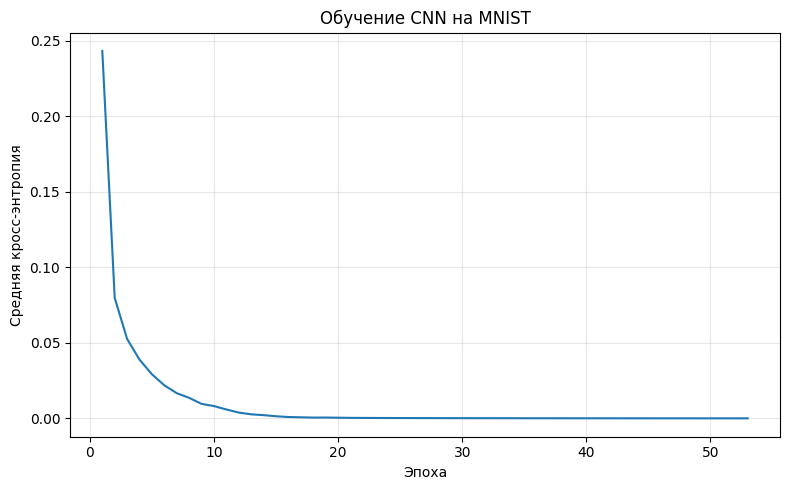

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history_table["epoch"], history_table["loss"])
ax.set(
    xlabel="Эпоха",
    ylabel="Средняя кросс-энтропия",
    title="Обучение CNN на MNIST",
)
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "loss.png", dpi=150)
plt.show()


## 9. ROC-кривые и AUC



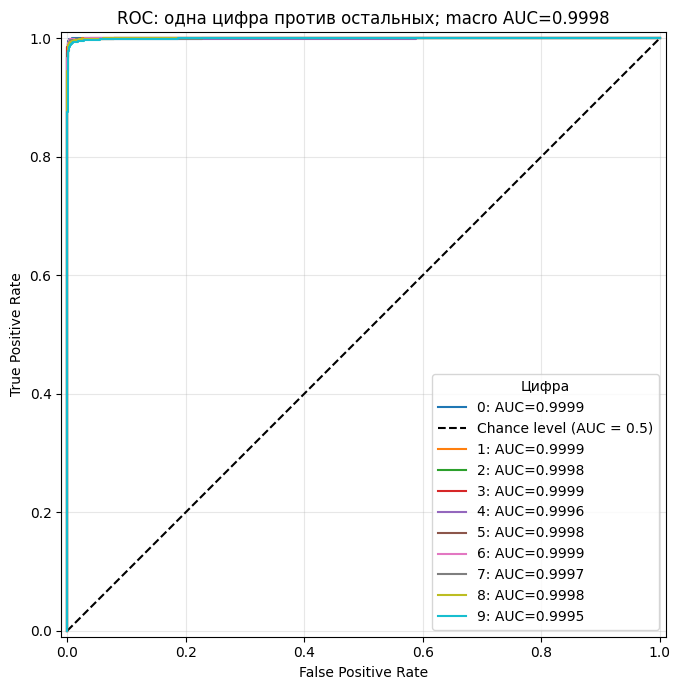

In [ ]:
fig, ax = plt.subplots(figsize=(9, 7))
for digit in classes:
    binary_labels = y_test == digit
    digit_auc = roc_auc_score(binary_labels, probabilities[:, digit])
    curve_label = f"{digit}: AUC={digit_auc:.4f}"
    RocCurveDisplay.from_predictions(
        binary_labels,
        probabilities[:, digit],
        name=str(digit),
        curve_kwargs={"label": curve_label},
        plot_chance_level=(digit == 0),
        ax=ax,
    )
ax.set(
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    title=f"ROC: одна цифра против остальных; macro AUC={macro_auc:.4f}",
)
ax.legend(loc="lower right", title="Цифра")
ax.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "roc.png", dpi=150)
plt.show()


## 10. Матрица ошибок



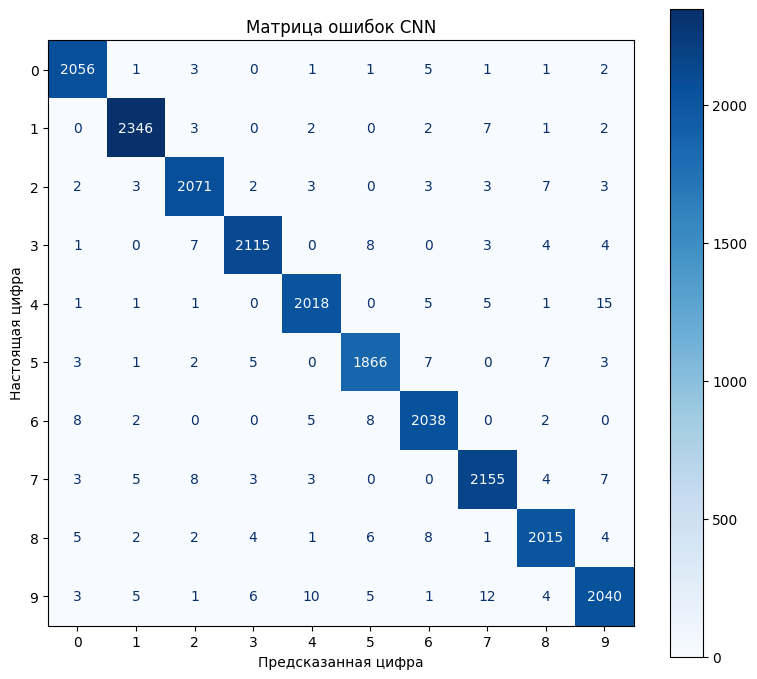

In [ ]:
fig, ax = plt.subplots(figsize=(8, 7))
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predicted,
    labels=classes,
    display_labels=classes,
    cmap="Blues",
    values_format="d",
    ax=ax,
)
ax.set(
    xlabel="Предсказанная цифра",
    ylabel="Настоящая цифра",
    title="Матрица ошибок CNN",
)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "confusion_matrix.png", dpi=150)
plt.show()


## 11. Посмотрим ошибочные предсказания


Ошибок: 280 из 21000


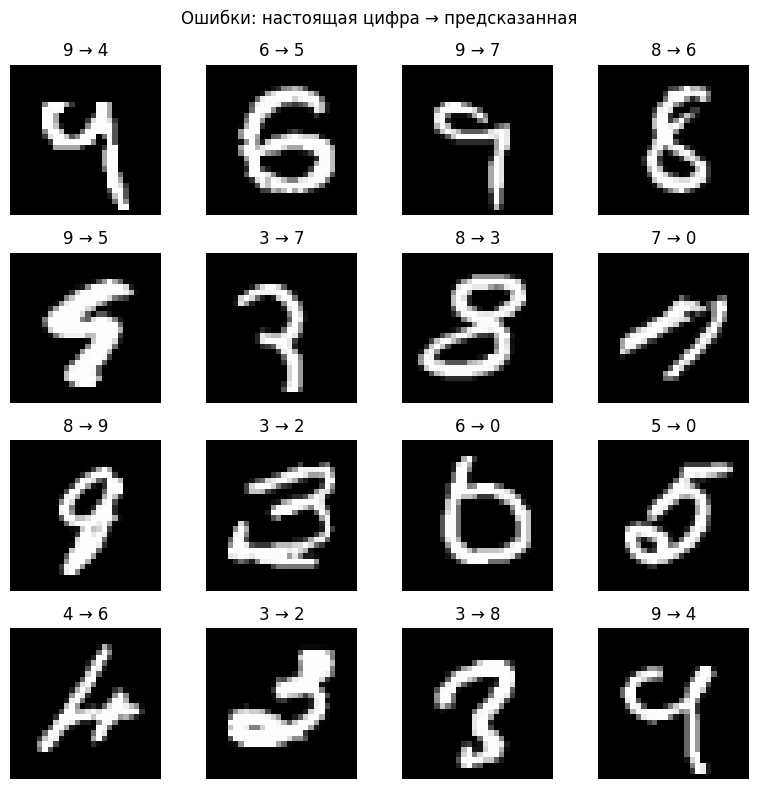

In [ ]:
errors = np.flatnonzero(predicted != y_test)
print(f"Ошибок: {errors.size} из {y_test.size}")

if errors.size:
    fig, axes = plt.subplots(4, 4, figsize=(8, 8))
    for axis in axes.flat:
        axis.axis("off")
    for index, axis in zip(errors[:16], axes.flat):
        axis.imshow(X_test[index, 0], cmap="gray", vmin=0, vmax=1)
        axis.set_title(f"{y_test[index]} → {predicted[index]}")
    fig.suptitle("Ошибки: настоящая цифра → предсказанная")
    fig.tight_layout()
    fig.savefig(IMAGES_DIR / "errors.png", dpi=150)
    plt.show()
else:
    print("Ошибок на тестовой выборке нет.")
